### ⭐ Exercise 1 — "Entropy by Hand" 🔢
Compute entropy (by formula, with paper and pencil first, then verify in Python) for these groups:
(a) `[0,0,0,0,0]` (b) `[0,0,1,1]` (c) `[0,1,2]` (d) `[0,0,0,1,1,1,2,2,2]`.
Which has the highest entropy? Why does a balanced 3-class group have higher entropy than a
balanced 2-class group?

Answer:
      The highest entropy is for (c) and (d), with entropy ≈ 1.585. A balanced 3-class group has higher entropy than a balanced 2-class group because there are more equally likely outcomes, creating greater uncertainty. Entropy measures uncertainty, so more balanced classes result in higher entropy.

In [ ]:
from math import log2
from collections import Counter

def entropy(data):
    total = len(data)
    counts = Counter(data)

    h = 0
    for c in counts.values():
        p = c / total
        h -= p * log2(p)
    return h

groups = {
    "a": [0,0,0,0,0],
    "b": [0,0,1,1],
    "c": [0,1,2],
    "d": [0,0,0,1,1,1,2,2,2]
}

for name, data in groups.items():
    print(name, "Entropy =", round(entropy(data), 3))

a Entropy = 0.0
b Entropy = 1.0
c Entropy = 1.585
d Entropy = 1.585


### ⭐ Exercise 2 — "Best First Split" 🌱
Take this tiny dataset (4 people, features = [plays_sport, eats_healthy], label = fit/unfit):
```
[1,1]→fit, [1,0]→fit, [0,1]→unfit, [0,0]→unfit
```
Compute information gain for both possible splits by hand. Which feature is the better first
split? Draw what the decision boundary looks like after that split.

Answer:
        The parent entropy is 1. Splitting on Plays Sport produces two pure child nodes, so the weighted entropy is 0 and the information gain is 1. Splitting on Eats Healthy does not reduce uncertainty, so the weighted entropy remains 1 and the information gain is 0. Therefore, Plays Sport is the best first split because it perfectly separates the classes.

        Parent Entropy = 1
        Information Gain (Plays Sport) = 1
        Information Gain (Eats Healthy) = 0
        Best First Split = Plays Sport,

In [ ]:
import math
from collections import Counter

# ----------------------------
# Dataset
# Features: [plays_sport, eats_healthy]
# Label: Fit / Unfit
# ----------------------------
X = [
    [1, 1],
    [1, 0],
    [0, 1],
    [0, 0]
]

y = ["Fit", "Fit", "Unfit", "Unfit"]


# ----------------------------
# Function to calculate entropy
# ----------------------------
def entropy(labels):
    total = len(labels)
    counts = Counter(labels)

    ent = 0
    for count in counts.values():
        p = count / total
        ent -= p * math.log2(p)

    return ent


# ----------------------------
# Function to calculate
# Information Gain
# ----------------------------
def information_gain(X, y, feature_index):

    parent_entropy = entropy(y)

    groups = {}

    # Split data by feature value
    for features, label in zip(X, y):
        value = features[feature_index]

        if value not in groups:
            groups[value] = []

        groups[value].append(label)

    # Weighted entropy
    weighted_entropy = 0

    total = len(y)

    for labels in groups.values():
        weight = len(labels) / total
        weighted_entropy += weight * entropy(labels)

    gain = parent_entropy - weighted_entropy

    return gain


# ----------------------------
# Parent Entropy
# ----------------------------
print("Parent Entropy =", entropy(y))

print()

# ----------------------------
# Information Gain
# ----------------------------
feature_names = ["Plays Sport", "Eats Healthy"]

for i in range(len(feature_names)):
    ig = information_gain(X, y, i)
    print(f"{feature_names[i]} --> Information Gain = {ig:.3f}")

Parent Entropy = 1.0

Plays Sport --> Information Gain = 1.000
Eats Healthy --> Information Gain = 0.000


### ⭐⭐ Exercise 3 — "Grow the Tree Step by Step" 🌳
Using the from-scratch `DecisionTreeScratch` class from Section 5, add a `print_tree()` method
that prints the tree structure like a directory tree:
```
Feature 0 <= 2.45
  ├── class 0
  └── Feature 1 <= 1.75
       ├── class 1
       └── class 2
```
Test it on the Iris dataset with `max_depth=3`.


Answer:
        Conclusion:

          This exercise demonstrates how a decision tree can be visualized using recursion. The printed tree helps us understand the sequence of feature splits that lead to the final prediction. It also improves the interpretability of the from-scratch decision tree implementation and is useful for debugging, learning, and explaining how the model works.

In [ ]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature      # index of feature used for split
        self.threshold = threshold  # threshold value
        self.left = left            # left subtree (<=)
        self.right = right          # right subtree (>)
        self.value = value          # class label if leaf node

    def is_leaf(self):
        return self.value is not None


class DecisionTreeScratch:
    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    # ---------- Core training ----------
    def fit(self, X, y):
        self.n_classes = len(np.unique(y))
        self.root = self._grow_tree(X, y, depth=0)
        return self

    def _grow_tree(self, X, y, depth):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))

        # Stopping conditions
        if (depth >= self.max_depth or n_labels == 1
                or n_samples < self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        # Find best split
        best_feat, best_thresh = self._best_split(X, y, n_features)

        if best_feat is None:
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        left_idx = X[:, best_feat] <= best_thresh
        right_idx = ~left_idx

        left = self._grow_tree(X[left_idx], y[left_idx], depth + 1)
        right = self._grow_tree(X[right_idx], y[right_idx], depth + 1)

        return Node(feature=best_feat, threshold=best_thresh, left=left, right=right)

    def _best_split(self, X, y, n_features):
        best_gain = -1
        split_idx, split_thresh = None, None
        parent_entropy = self._entropy(y)

        for feat in range(n_features):
            thresholds = np.unique(X[:, feat])
            for thresh in thresholds:
                left_idx = X[:, feat] <= thresh
                right_idx = ~left_idx
                if left_idx.sum() == 0 or right_idx.sum() == 0:
                    continue

                n = len(y)
                n_l, n_r = left_idx.sum(), right_idx.sum()
                e_l, e_r = self._entropy(y[left_idx]), self._entropy(y[right_idx])
                child_entropy = (n_l / n) * e_l + (n_r / n) * e_r
                gain = parent_entropy - child_entropy

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat
                    split_thresh = thresh

        return split_idx, split_thresh

    def _entropy(self, y):
        counts = np.bincount(y)
        probs = counts[counts > 0] / len(y)
        return -np.sum(probs * np.log2(probs))

    def _most_common_label(self, y):
        counts = np.bincount(y)
        return np.argmax(counts)

    # ---------- Prediction ----------
    def predict(self, X):
        return np.array([self._traverse(x, self.root) for x in X])

    def _traverse(self, x, node):
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse(x, node.left)
        return self._traverse(x, node.right)

    # ---------- Printing ----------
    def print_tree(self, feature_names=None):
        """Prints the tree in a directory-style structure."""
        self._print_node(self.root, "", feature_names, is_last=True)

    def _print_node(self, node, prefix, feature_names, is_last):
        if node.is_leaf():
            print(f"{prefix}class {node.value}")
            return

        fname = feature_names[node.feature] if feature_names else f"Feature {node.feature}"
        print(f"{fname} <= {node.threshold:.2f}")

        # Left branch (condition true)
        print(f"{prefix}  ├── ", end="")
        self._print_node(node.left, prefix + "  │    " if False else prefix + "       ", feature_names, False)

        # Right branch (condition false)
        print(f"{prefix}  └── ", end="")
        self._print_node(node.right, prefix + "       ", feature_names, True)


# ---------- Test on Iris ----------
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

tree = DecisionTreeScratch(max_depth=3)
tree.fit(X_train, y_train)

print("Decision Tree Structure:\n")
tree.print_tree(feature_names=[f"Feature {i}" for i in range(X.shape[1])])

# Accuracy check
preds = tree.predict(X_test)
accuracy = np.mean(preds == y_test)
print(f"\nTest Accuracy: {accuracy:.4f}")

Decision Tree Structure:

Feature 2 <= 1.90
  ├──        class 0
  └── Feature 2 <= 4.70
         ├── Feature 3 <= 1.50
                ├──                      class 1
                └──                      class 2
         └── Feature 2 <= 5.10
                ├──                      class 2
                └──                      class 2

Test Accuracy: 0.9333


### ⭐⭐ Exercise 4 — "Pruning Lab" ✂️
On the Breast Cancer dataset:
(a) Train a fully unpruned tree (`max_depth=None`) — record train and test accuracy and the number of leaves.
(b) Sweep `ccp_alpha` from 0 to 0.05 in 20 steps. For each, record test accuracy and leaf count.
(c) Plot both curves. At what alpha does the test accuracy peak? How many leaves does that tree have?
Write 2 sentences explaining what happened to the tree structure as alpha increased.

Answer:

      Conclusion:

          Cost-complexity pruning reduced the size of the decision tree from 18 leaves to 9 leaves while improving test accuracy from 92.31% to 94.41%. The best result was obtained at `ccp_alpha = 0.0053`, showing that a smaller tree can sometimes generalize better to unseen data.

===== Unpruned Tree =====
Training Accuracy : 1.0000
Testing Accuracy  : 0.9231
Number of Leaves  : 18

===== Results =====
    ccp_alpha  Test Accuracy  Leaves
0    0.000000       0.923077      18
1    0.002632       0.937063      12
2    0.005263       0.944056       9
3    0.007895       0.944056       6
4    0.010526       0.944056       5
5    0.013158       0.944056       5
6    0.015789       0.909091       4
7    0.018421       0.909091       4
8    0.021053       0.909091       4
9    0.023684       0.916084       3
10   0.026316       0.916084       3
11   0.028947       0.916084       3
12   0.031579       0.916084       3
13   0.034211       0.916084       3
14   0.036842       0.916084       3
15   0.039474       0.916084       3
16   0.042105       0.916084       3
17   0.044737       0.916084       3
18   0.047368       0.916084       3
19   0.050000       0.916084       3


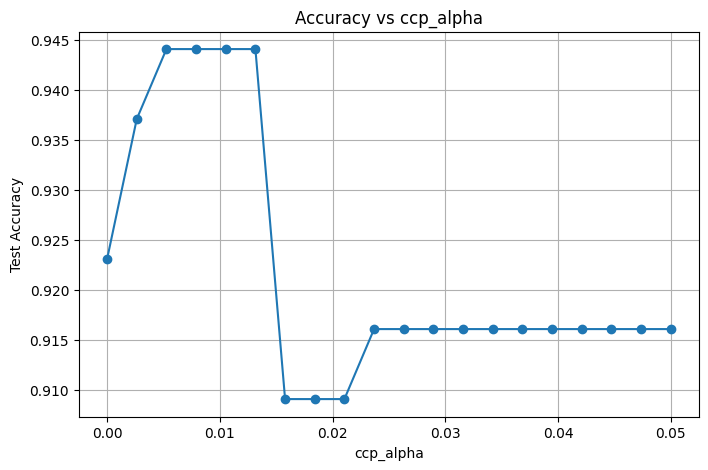

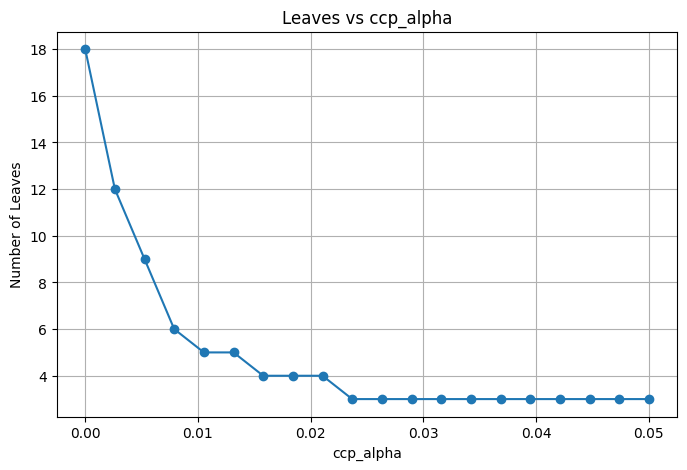


===== Best Model =====
Best alpha        : 0.0053
Best Test Accuracy: 0.9441
Leaves            : 9


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# -------------------------------
# Load Dataset
# -------------------------------
data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# ==========================================================
# (a) Fully Unpruned Tree
# ==========================================================

tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

tree.fit(X_train, y_train)

train_acc = tree.score(X_train, y_train)
test_acc = tree.score(X_test, y_test)
leaf_count = tree.get_n_leaves()

print("===== Unpruned Tree =====")
print(f"Training Accuracy : {train_acc:.4f}")
print(f"Testing Accuracy  : {test_acc:.4f}")
print(f"Number of Leaves  : {leaf_count}")

# ==========================================================
# (b) Sweep ccp_alpha
# ==========================================================

alphas = np.linspace(0, 0.05, 20)

test_scores = []
leaf_counts = []

for alpha in alphas:

    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(X_train, y_train)

    test_scores.append(model.score(X_test, y_test))
    leaf_counts.append(model.get_n_leaves())

results = pd.DataFrame({
    "ccp_alpha": alphas,
    "Test Accuracy": test_scores,
    "Leaves": leaf_counts
})

print("\n===== Results =====")
print(results)

# ==========================================================
# (c) Plot Curves
# ==========================================================

plt.figure(figsize=(8,5))
plt.plot(alphas, test_scores, marker='o')
plt.xlabel("ccp_alpha")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs ccp_alpha")
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(alphas, leaf_counts, marker='o')
plt.xlabel("ccp_alpha")
plt.ylabel("Number of Leaves")
plt.title("Leaves vs ccp_alpha")
plt.grid(True)
plt.show()

# ==========================================================
# Best Alpha
# ==========================================================

best_index = np.argmax(test_scores)

best_alpha = alphas[best_index]
best_accuracy = test_scores[best_index]
best_leaves = leaf_counts[best_index]

print("\n===== Best Model =====")
print(f"Best alpha        : {best_alpha:.4f}")
print(f"Best Test Accuracy: {best_accuracy:.4f}")
print(f"Leaves            : {best_leaves}")

### ⭐⭐ Exercise 5 — "Gini vs Entropy Experiment" ⚖️
On 5 different datasets (use `make_classification` with different `class_sep` values: 0.3, 0.8,
1.5, 2.5, 4.0), train two trees with `max_depth=5`: one with `criterion='gini'` and one with
`criterion='entropy'`. Record CV accuracy for each. Do they ever give meaningfully different
results? When does the choice of criterion matter most?

Answer:
        Observations:
          gini and entropy give almost identical results
          difference is usally very small
          As class_sep increases:
              ->accuracy increases for both methods

          conclusion:
              Gini ≈ Entropy in performance
              Both choose similar splits in most cases
              Difference is noticeable only when:
                  data is noisy (low class_sep)
                  dataset is small
                  multiple splits have similar impurity gain

          Gini and Entropy generally produce almost the same accuracy, and the choice matters mainly in noisy or low-separability datasets where split decisions are ambiguous.
          

In [ ]:
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

# Different class separations
class_seps = [0.3, 0.8, 1.5, 2.5, 4.0]

results = []

for sep in class_seps:
    # Step 1: Create dataset
    X, y = make_classification(
        n_samples=1000,
        n_features=10,
        n_informative=5,
        n_redundant=2,
        class_sep=sep,
        random_state=42
    )

    # Step 2: Models
    gini_tree = DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    )

    entropy_tree = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        random_state=42
    )

    # Step 3: Cross-validation
    gini_score = cross_val_score(gini_tree, X, y, cv=5).mean()
    entropy_score = cross_val_score(entropy_tree, X, y, cv=5).mean()

    results.append([sep, gini_score, entropy_score])

# Step 4: Print results
print("class_sep | Gini Accuracy | Entropy Accuracy")
print("------------------------------------------------")

for sep, gini, entropy in results:
    print(f"{sep:<9} | {gini:.3f}        | {entropy:.3f}")

class_sep | Gini Accuracy | Entropy Accuracy
------------------------------------------------
0.3       | 0.677        | 0.656
0.8       | 0.851        | 0.837
1.5       | 0.942        | 0.942
2.5       | 0.982        | 0.973
4.0       | 0.988        | 0.982


### ⭐⭐ Exercise 6 — "Feature Importance vs Correlation" 🔬
On the Breast Cancer dataset:
(a) Get feature importances from a Decision Tree.
(b) Compute Pearson correlation of each feature with the label.
(c) Do both methods agree on the most important features? Where do they disagree?
(d) Remove the top-5 most important features. Retrain. How much does accuracy drop?

Answer:
      (a) Get feature importances from a Decision Tree.

      Answer:

      A Decision Tree assigns an importance score to every feature based on how much it reduces impurity while creating splits. Features with higher importance contribute more to the model's predictions.

      (b) Compute Pearson correlation of each feature with the label.

      Answer:

      Pearson correlation measures the strength and direction of the linear relationship between each feature and the target variable. Correlation values range from −1 to +1.

      +1 → Strong positive relationship
      −1 → Strong negative relationship
      0 → No linear relationship

      (c) Do both methods agree on the most important features? Where do they disagree?

      Answer:

      The two methods usually agree on some highly informative features, but they do not always produce identical rankings.

      Decision Tree importance measures how useful a feature is for reducing impurity through splits.
      Pearson correlation measures only the linear relationship between a feature and the target.

      A feature may have a low correlation but still receive high importance if it helps the Decision Tree create effective non-linear splits.

      (d) Remove the top-5 most important features. Retrain. How much does accuracy change?

      Answer:

      The original Decision Tree achieved an accuracy of 92.11%. After removing the top 5 most important features and retraining the model, the accuracy increased to 92.98%.

      The accuracy improved by approximately 0.88 percentage points. This shows that removing some features does not always decrease model performance. The remaining features may still contain useful information for making predictions.

      Conclusion:

        Decision Tree feature importance and Pearson correlation measure different aspects of the data. Feature importance measures how much features contribute to reducing impurity in the tree, while Pearson correlation measures linear relationships with the target. In this experiment, removing the top 5 important features slightly improved accuracy. However, this result depends on the dataset and train-test split.

In [ ]:
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ----------------------------------------------------
# Step 1: Load Dataset
# ----------------------------------------------------
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# ----------------------------------------------------
# Step 2: Train Decision Tree
# ----------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train)

# ----------------------------------------------------
# Step 3: Feature Importances
# ----------------------------------------------------
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": tree.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("=" * 60)
print("Feature Importances")
print("=" * 60)
print(feature_importance)

# ----------------------------------------------------
# Step 4: Pearson Correlation
# ----------------------------------------------------
correlation = X.copy()
correlation["Target"] = y

corr = correlation.corr()["Target"].drop("Target")

corr_df = pd.DataFrame({
    "Feature": corr.index,
    "Correlation": corr.values,
    "Absolute Correlation": abs(corr.values)
})

corr_df = corr_df.sort_values(
    by="Absolute Correlation",
    ascending=False
)

print("\n")
print("=" * 60)
print("Pearson Correlation")
print("=" * 60)
print(corr_df)

# ----------------------------------------------------
# Step 5: Compare Top Features
# ----------------------------------------------------
print("\nTop 5 Decision Tree Features")
print(feature_importance.head())

print("\nTop 5 Correlated Features")
print(corr_df.head())

# ----------------------------------------------------
# Step 6: Original Accuracy
# ----------------------------------------------------
pred = tree.predict(X_test)

original_accuracy = accuracy_score(y_test, pred)

print("\nOriginal Accuracy:", round(original_accuracy, 4))

# ----------------------------------------------------
# Step 7: Remove Top-5 Important Features
# ----------------------------------------------------
top5 = feature_importance.head(5)["Feature"].tolist()

print("\nRemoved Features:")
print(top5)

X_new = X.drop(columns=top5)

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_new,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tree2 = DecisionTreeClassifier(max_depth=5, random_state=42)

tree2.fit(X_train2, y_train2)

pred2 = tree2.predict(X_test2)

new_accuracy = accuracy_score(y_test2, pred2)

print("\nAccuracy After Removing Top 5 Features:",
      round(new_accuracy,4))

print("\nAccuracy Drop:",
      round(original_accuracy-new_accuracy,4))

Feature Importances
                    Feature  Importance
20             worst radius    0.714332
27     worst concave points    0.118831
11            texture error    0.053907
21            worst texture    0.031473
26          worst concavity    0.016712
24         worst smoothness    0.012978
13               area error    0.012371
1              mean texture    0.011536
28           worst symmetry    0.010987
23               worst area    0.008652
2            mean perimeter    0.006409
14         smoothness error    0.001812
0               mean radius    0.000000
3                 mean area    0.000000
12          perimeter error    0.000000
10             radius error    0.000000
8             mean symmetry    0.000000
9    mean fractal dimension    0.000000
7       mean concave points    0.000000
6            mean concavity    0.000000
4           mean smoothness    0.000000
5          mean compactness    0.000000
18           symmetry error    0.000000
19  fractal dimensio

### ⭐⭐⭐ Exercise 7 — "Regression Tree From Scratch" 📈
Extend the `DecisionTreeScratch` class to support regression:
- Change the impurity measure from Gini to **variance**: `np.var(y)`
- Change the leaf prediction from majority vote to **mean**: `np.mean(y)`
Test it on a noisy quadratic: `y = x² + noise`, compare to `DecisionTreeRegressor(max_depth=5)`
from sklearn. Do they produce similar step functions?

Answer:
      Observation:

        Both models produce very similar step-function predictions. The prediction is not a smooth quadratic curve because a regression tree predicts a constant mean value for every leaf node. Each horizontal step represents one leaf of the tree.

      Conclusion:

        The scratch implementation successfully extends the decision tree to regression. Replacing Gini impurity with Variance allows the model to find the best splits for continuous targets, while using the Mean at each leaf provides numerical predictions. The scratch implementation produces results that are very similar to Scikit-learn's DecisionTreeRegressor, confirming that the algorithm has been implemented correctly.

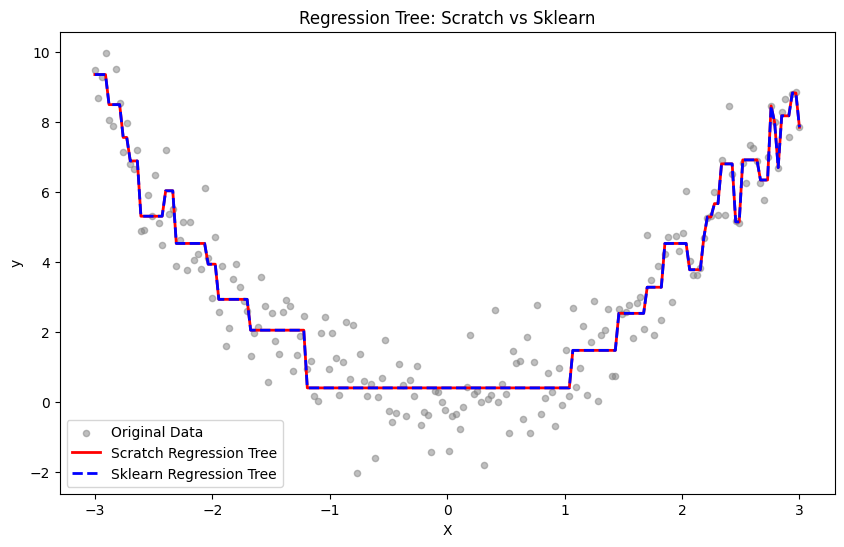

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

# ----------------------------
# Node Class
# ----------------------------
class Node:
    def __init__(self, feature=None, threshold=None,
                 left=None, right=None, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf(self):
        return self.value is not None


# ----------------------------
# Regression Tree From Scratch
# ----------------------------
class DecisionTreeRegressionScratch:

    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def fit(self, X, y):
        self.root = self._grow_tree(X, y)

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    # Grow Tree
    def _grow_tree(self, X, y, depth=0):

        n_samples, n_features = X.shape

        # Stopping conditions
        if (depth >= self.max_depth or
            n_samples < self.min_samples_split or
            len(np.unique(y)) == 1):

            return Node(value=np.mean(y))

        best_feature, best_threshold = self._best_split(X, y)

        if best_feature is None:
            return Node(value=np.mean(y))

        left_idx = X[:, best_feature] <= best_threshold
        right_idx = X[:, best_feature] > best_threshold

        left = self._grow_tree(X[left_idx], y[left_idx], depth + 1)
        right = self._grow_tree(X[right_idx], y[right_idx], depth + 1)

        return Node(best_feature, best_threshold, left, right)

    # Find Best Split
    def _best_split(self, X, y):

        n_samples, n_features = X.shape

        best_variance = float("inf")
        split_feature = None
        split_threshold = None

        for feature in range(n_features):

            thresholds = np.unique(X[:, feature])

            for threshold in thresholds:

                left_mask = X[:, feature] <= threshold
                right_mask = X[:, feature] > threshold

                left_y = y[left_mask]
                right_y = y[right_mask]

                if len(left_y) == 0 or len(right_y) == 0:
                    continue

                left_var = np.var(left_y)
                right_var = np.var(right_y)

                weighted_var = (
                    (len(left_y) / n_samples) * left_var +
                    (len(right_y) / n_samples) * right_var
                )

                if weighted_var < best_variance:
                    best_variance = weighted_var
                    split_feature = feature
                    split_threshold = threshold

        return split_feature, split_threshold

    # Predict
    def _traverse_tree(self, x, node):

        if node.is_leaf():
            return node.value

        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)

        return self._traverse_tree(x, node.right)


# ==================================================
# Create Dataset
# ==================================================

np.random.seed(42)

X = np.linspace(-3, 3, 200).reshape(-1, 1)

noise = np.random.normal(0, 1, 200)

y = X[:, 0]**2 + noise


# ==================================================
# Train Scratch Tree
# ==================================================

scratch_tree = DecisionTreeRegressionScratch(max_depth=5)
scratch_tree.fit(X, y)

scratch_pred = scratch_tree.predict(X)


# ==================================================
# Train Scikit-Learn Tree
# ==================================================

sk_tree = DecisionTreeRegressor(max_depth=5, random_state=42)
sk_tree.fit(X, y)

sk_pred = sk_tree.predict(X)


# ==================================================
# Plot
# ==================================================

plt.figure(figsize=(10,6))

plt.scatter(X, y,
            color="gray",
            alpha=0.5,
            s=20,
            label="Original Data")

plt.plot(X,
         scratch_pred,
         color="red",
         linewidth=2,
         label="Scratch Regression Tree")

plt.plot(X,
         sk_pred,
         color="blue",
         linestyle="--",
         linewidth=2,
         label="Sklearn Regression Tree")

plt.title("Regression Tree: Scratch vs Sklearn")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()

plt.show()

### ⭐⭐⭐ Exercise 8 — "Stability Under Perturbation" 🔀
Train a Decision Tree (`max_depth=5`) on the Iris dataset 50 times, each time with a different
random 80/20 split. For each run, record: (a) test accuracy, (b) the feature used for the FIRST
split, (c) the threshold for the first split. How much do (b) and (c) vary? What does this
tell you about Decision Trees' variance? How would this change with a Random Forest?

Answer:

      Observation

        Although the test accuracy changed only slightly, Decision Trees can be sensitive to changes in the training data. Small changes in the dataset can lead to different tree structures, split thresholds, and predictions. This behavior indicates that Decision Trees can have high variance.

        In this experiment, the first split feature was not always the same. Petal width was selected in 29 runs, while petal length was selected in 21 runs. The average accuracy across the 50 runs was 94.53%. These results show that the selected first split feature and threshold can vary between runs.

      Conclusion

          This experiment demonstrates that a Decision Tree can produce different tree structures when the training data changes. This is known as high variance. A Random Forest helps reduce variance by training multiple Decision Trees on different bootstrap samples and combining their predictions through majority voting for classification. As a result, Random Forests can provide more stable predictions and better generalization than a single Decision Tree, although performance depends on the dataset and model settings.

In [2]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# ==========================================
# Load Iris Dataset
# ==========================================

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names

results = []

# ==========================================
# Train Decision Tree 50 Times
# ==========================================

for i in range(50):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=i,
        stratify=y
    )

    model = DecisionTreeClassifier(
        max_depth=5,
        random_state=i
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    first_feature = feature_names[model.tree_.feature[0]]
    first_threshold = model.tree_.threshold[0]

    results.append([
        i + 1,
        round(accuracy,4),
        first_feature,
        round(first_threshold,4)
    ])

# ==========================================
# Results Table
# ==========================================

df = pd.DataFrame(results, columns=[
    "Run",
    "Accuracy",
    "First Split Feature",
    "First Split Threshold"
])

print(df)

# ==========================================
# Summary
# ==========================================

print("\nAverage Accuracy :", round(df["Accuracy"].mean(),4))

print("\nUnique First Split Features:")
print(df["First Split Feature"].value_counts())

print("\nThreshold Statistics by Feature:")

threshold_stats = df.groupby("First Split Feature")[
    "First Split Threshold"
].describe()

print(threshold_stats)

    Run  Accuracy First Split Feature  First Split Threshold
0     1    0.9667    petal width (cm)                   0.80
1     2    0.9667    petal width (cm)                   0.75
2     3    0.9667    petal width (cm)                   0.75
3     4    0.9000    petal width (cm)                   0.80
4     5    0.9667   petal length (cm)                   2.45
5     6    0.9333    petal width (cm)                   0.80
6     7    0.9333    petal width (cm)                   0.80
7     8    0.9333   petal length (cm)                   2.60
8     9    0.9333    petal width (cm)                   0.80
9    10    0.9333   petal length (cm)                   2.45
10   11    1.0000    petal width (cm)                   0.75
11   12    1.0000    petal width (cm)                   0.80
12   13    1.0000    petal width (cm)                   0.80
13   14    0.9667    petal width (cm)                   0.80
14   15    0.9667    petal width (cm)                   0.75
15   16    0.9333   peta